# Answer for Question 2


### 1. Import all necessary library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error


### 2. Load dataset

In [2]:
data = pd.read_csv('/content/dataset_q2_q4 (1).csv')

In [3]:
# Explor dataset
data.head()

,x1,x2,x3,y_label
0,-100.838182,100.000000,0.000000,-6.908485e+06
1,-98.826004,101.202405,0.901804,-7.167624e+06
2,-98.627987,102.404810,1.803607,-7.429470e+06
3,-96.960173,103.607214,2.705411,-7.699765e+06
4,-97.190325,104.809619,3.607214,-7.972486e+06


#### 3. Splitting the Data into Features and Target Variables

In [4]:
X = data[['x1', 'x2', 'x3']].values
y = data['y_label'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)


In [5]:
# Initialize parameters
theta = np.random.randn(4)
learning_rate = 0.001
epochs = 1000
m = len(y_train)
loss_history = []


#### 3.Hypothesis Function

In [6]:
def hypothesis(X, theta):
    return (3 * theta[1] * X[:, 0]**2 + theta[2] * X[:, 0] * X[:, 1] -
            theta[3] * X[:, 1]**2 + theta[2] * theta[3] * X[:, 2] + theta[0])

#### 4.Cost Function to Measure Model Performance

In [7]:
def compute_cost(X, y, theta):
    predictions = hypothesis(X, theta)
    cost = np.sum((predictions - y) ** 2) / (2 * m)
    return cost



#### 5.Gradient Descent Optimization

Epoch 0, Cost: 2.0174568256286625e+47
NaN detected in cost. Check calculations or try lower learning rate.


<ipython-input-7-440937e816b0>:3: RuntimeWarning: overflow encountered in square
  cost = np.sum((predictions - y) ** 2) / (2 * m)
<ipython-input-6-1b028e969511>:3: RuntimeWarning: overflow encountered in scalar multiply
  theta[3] * X[:, 1]**2 + theta[2] * theta[3] * X[:, 2] + theta[0])
<ipython-input-6-1b028e969511>:3: RuntimeWarning: invalid value encountered in multiply
  theta[3] * X[:, 1]**2 + theta[2] * theta[3] * X[:, 2] + theta[0])


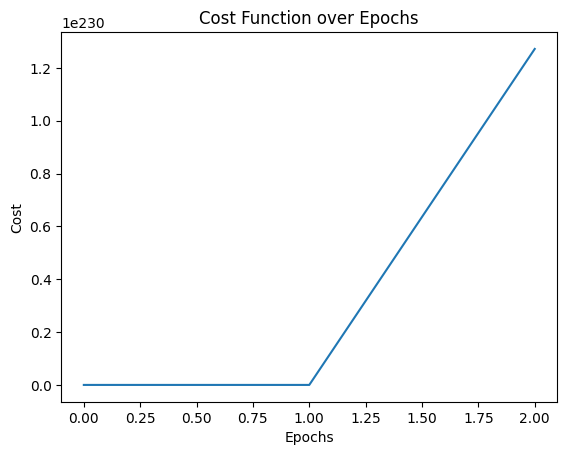

Optimal theta values: [-1.01572898e+234 -1.06064183e+239 -9.38860274e+238 -2.65612527e+239]


In [8]:
for epoch in range(epochs):
    y_pred = hypothesis(X_train, theta)
    gradients = np.array([
        np.sum(y_pred - y_train) / m,
        np.sum((y_pred - y_train) * 3 * X_train[:, 0]**2) / m,
        np.sum((y_pred - y_train) * X_train[:, 0] * X_train[:, 1]) / m,
        np.sum((y_pred - y_train) * X_train[:, 1]**2) / m
    ])
    theta -= learning_rate * gradients
    cost = compute_cost(X_train, y_train, theta)


    if np.isnan(cost):
        print("NaN detected in cost. Check calculations or try lower learning rate.")
        break

    loss_history.append(cost)
    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Cost: {cost}")


plt.plot(range(len(loss_history)), loss_history)
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.title("Cost Function over Epochs")
plt.show()


print("Optimal theta values:", theta)

#### 6. Using PyTorch



Epoch 0, Loss: 0.6300334930419922
Epoch 100, Loss: 0.5810410976409912
Epoch 200, Loss: 0.546427309513092
Epoch 300, Loss: 0.5213208198547363
Epoch 400, Loss: 0.5025096535682678
Epoch 500, Loss: 0.48787593841552734
Epoch 600, Loss: 0.4760228991508484
Epoch 700, Loss: 0.4660288095474243
Epoch 800, Loss: 0.45728567242622375
Epoch 900, Loss: 0.4493919909000397


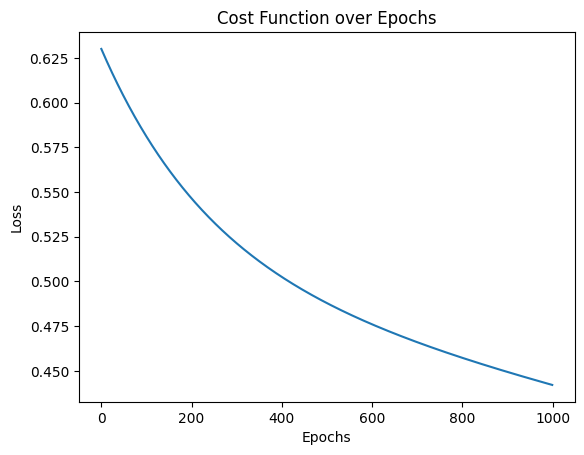

Optimal theta values: tensor([ 0.1093, -0.2374,  0.9560,  0.0220], requires_grad=True)


In [9]:
import torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_normalized = scaler_X.fit_transform(X_train)
y_train_normalized = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()

X_train_tensor = torch.tensor(X_train_normalized, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_normalized, dtype=torch.float32)

theta = torch.randn(4, requires_grad=True, dtype=torch.float32)
learning_rate = 0.0001
epochs = 1000
loss_history = []

def hypothesis(X, theta):
    return (3 * theta[1] * X[:, 0]**2 + theta[2] * X[:, 0] * X[:, 1] -
            theta[3] * X[:, 1]**2 + theta[2] * theta[3] * X[:, 2] + theta[0])

for epoch in range(epochs):
    if theta.grad is not None:
        theta.grad.zero_()

    y_pred = hypothesis(X_train_tensor, theta)

    loss = torch.mean((y_pred - y_train_tensor) ** 2) / 2
    loss_history.append(loss.item())

    if torch.isnan(loss):
        print("NaN detected in loss. Try adjusting the learning rate or checking computations.")
        break

    loss.backward()

    with torch.no_grad():
        theta -= learning_rate * theta.grad
        theta.grad.zero_()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item()}")

plt.plot(range(len(loss_history)), loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Cost Function over Epochs")
plt.show()

print("Optimal theta values:", theta)

# Answer for Question 3 : Implementing Linear Regression Models with Scikit-Learn


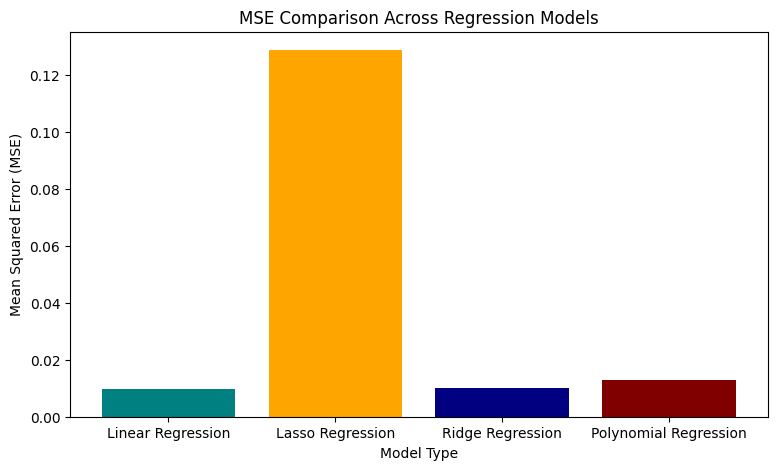

                   Model  Mean Squared Error
0      Linear Regression            0.009639
1       Lasso Regression            0.128593
2       Ridge Regression            0.010134
3  Polynomial Regression            0.013011


In [10]:


X, y = make_regression(n_samples=800, n_features=15, noise=0.1, random_state=10)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
mse_linear = mean_squared_error(y_test, y_pred_linear)

lasso_model = Lasso(alpha= 0.1)
lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)

ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)

polynomial_features = PolynomialFeatures(degree=2)
poly_model = make_pipeline(polynomial_features, LinearRegression())
poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)
mse_poly = mean_squared_error(y_test, y_pred_poly)

models = ['Linear Regression', 'Lasso Regression', 'Ridge Regression', 'Polynomial Regression']
mse_values = [mse_linear, mse_lasso, mse_ridge, mse_poly]

plt.figure(figsize=(9, 5))
plt.bar(models, mse_values, color=['teal', 'orange', 'navy', 'maroon'])
plt.xlabel('Model Type')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE Comparison Across Regression Models')
plt.show()


mse_comparison = pd.DataFrame({
    'Model': models,
    'Mean Squared Error': mse_values
})
print(mse_comparison)


# Q4 Solution: Implementing the Normal Equation

In [11]:


X, y = make_regression(n_samples=800, n_features=15, noise=0.1, random_state=10)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

X_train_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]

y_train = y_train.reshape(-1, 1)

theta = np.linalg.inv(X_train_b.T.dot(X_train_b)).dot(X_train_b.T).dot(y_train)


print("Optimal parameter values (theta):")
print(theta.ravel())



Optimal parameter values (theta):
[-6.66693731e-03  6.61706385e+01  4.36076360e+01  4.76378758e+01
  9.35039363e+01  3.91240469e-03 -3.39489422e-03 -3.01000346e-04
  5.04018673e+01  1.17757737e+01  6.53368844e+01  3.21377799e+01
  6.24339199e+01  3.69844213e+01 -4.89369413e-03 -1.44905762e-03]
